## Ferramentas
Como ferramental, estou utilizando Jupyter Notebook rodando através do Visual Studio Code. <br>

## Caso de referência
Salvador — BA: escolas municipais de educação básica, 8 grupos nutricionais,
11 meses letivos (fevereiro a dezembro), horizonte de 20 dias úteis por mês. <br>

**Origem dos dados** <br>
Módulo 1 — Alimentos : `alimentos_elegiveis_otimizador.csv` (com `is_ingrediente`) <br>
Módulo 2 — Censo     : `demanda_nutricional_escolas.csv` <br>
Módulo 3 — Preços    : `resumo_precos_referencia.csv`, `sazonalidade_por_produto.csv` <br>
Módulo 4 — Regras    : `restricoes_pnae.json`, `parametros_nutricionais_solver.csv` <br>

**Nota metodológica — Janeiro** <br>
Janeiro é excluído por ser mês de férias escolares no calendário letivo municipal
de Salvador-BA. Meses processados: fevereiro a dezembro (11 meses × 20 dias úteis = 220 dias).


# Módulo 5 — Otimizador de Programação Linear Inteira Mista (MILP)

Este notebook é a **interface de análise e documentação** do otimizador PNAE.
O motor computacional reside em `otimizacao_pnae_solver.py`, que é importado aqui.
Essa separação segue boa prática de engenharia de software: código reutilizável e
testável no `.py`; visualizações, narrativa e validação no notebook.

**Referências teóricas** <br>
Stigler (1945) — Problema da Dieta; Dantzig (1963) — Algoritmo Simplex; <br>
Resolução CD/FNDE nº 4, de 26 de fevereiro de 2026 — restrições regulatórias. <br>

**Modelo adotado: MILP — Mixed Integer Linear Program** <br>
A introdução de variáveis binárias de presença $y_{jd} \in \{0,1\}$ é necessária para
modelar restrições de frequência semanal e diversidade mínima de alimentos, tornando
o problema MILP. O solver CBC (COIN-OR), incluído no PuLP, resolve MILP nativamente.


---
## Índice

1. [Importações e configurações](#1-importacoes)
2. [Verificação do ambiente e dependências](#2-verificacao)
3. [Carregamento e diagnóstico das bases](#3-carregamento)
4. [Visão geral dos grupos nutricionais](#4-grupos)
5. [Execução do otimizador — todos os grupos e meses](#5-execucao)
   - 5.1 Parâmetros de execução
   - 5.2 Execução completa (11 meses × todos os grupos)
   - 5.3 Execução parcial (grupo e mês específicos — depuração)
6. [Análise dos resultados consolidados](#6-analise)
   - 6.1 Custo médio por grupo e por mês
   - 6.2 Sazonalidade de custo ao longo do ano
   - 6.3 Conformidade nutricional consolidada
   - 6.4 Indicadores de Agricultura Familiar
7. [Inspeção de cardápio — grupo e mês específicos](#7-inspecao)
   - 7.1 Cardápio semanal detalhado
   - 7.2 Distribuição de grupos alimentares
   - 7.3 Verificação das restrições PNAE
8. [Análise comparativa: março vs setembro (sazonalidade)](#8-sazonalidade)
9. [Análise de sensibilidade](#9-sensibilidade)
   - 9.1 Custo × percentual de Agricultura Familiar
   - 9.2 Custo × cobertura nutricional exigida
10. [Geração do relatório Word para nutricionistas](#10-relatorio)
11. [Exportação final consolidada](#11-exportacao)
12. [Sumário executivo](#12-sumario)

---


## 1. Importações e configurações <a id='1-importacoes'></a>

In [1]:
# Bibliotecas padrão
import os
import sys
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Motor do solver — importado do script Python do projeto
# Instalar dependência: pip install pulp
sys.path.insert(0, '.')   # garante que o .py na mesma pasta seja encontrado
from otimizacao_pnae_solver import (
    MESES_LETIVOS,
    NOMES_MESES,
    DIAS_UTEIS_MES,
    SEMANAS_MES,
    carregar_bases,
    preparar_dataset_solver,
    montar_perfil,
    construir_e_resolver,
    resolver_todos,
    ResultadoSolver,
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 80)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['font.size'] = 11

# ── Pastas ────────────────────────────────────────────────────────
output_folder = './data/output/'
os.makedirs(output_folder, exist_ok=True)

print(f"Módulo 5 — Otimizador MILP PNAE")
print(f"Iniciado em : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Pasta saída : {os.path.abspath(output_folder)}")
print(f"Solver      : otimizacao_pnae_solver.py")


Módulo 5 — Otimizador MILP PNAE
Iniciado em : 2026-09-08 10:44:05
Pasta saída : c:\Users\dba14\Documents\projeto\PNAE\data\output
Solver      : otimizacao_pnae_solver.py


## 2. Verificação do ambiente e dependências <a id='2-verificacao'></a>

In [2]:
# ── Verificar dependências críticas ──────────────────────────────
problemas = []

try:
    import pulp
    print(f"✓ PuLP          {pulp.__version__}")
except ImportError:
    problemas.append("PuLP não instalado — execute: pip install pulp")

try:
    import sklearn
    print(f"✓ scikit-learn  {sklearn.__version__}")
except ImportError:
    print("⚠ scikit-learn ausente (necessário para Módulos 1–3, não para este)")

try:
    import rapidfuzz
    print(f"✓ rapidfuzz     {rapidfuzz.__version__}")
except ImportError:
    print("⚠ rapidfuzz ausente (necessário para Módulo 3, não para este)")

# ── Verificar arquivos de entrada ─────────────────────────────────
print()
ARQUIVOS = {
    'alimentos_elegiveis_otimizador.csv' : 'Módulo 4',
    'parametros_nutricionais_solver.csv' : 'Módulo 4',
    'restricoes_pnae.json'               : 'Módulo 4',
    'resumo_precos_referencia.csv'       : 'Módulo 3',
    'demanda_nutricional_escolas.csv'    : 'Módulo 2',
}
OPCIONAIS = {'sazonalidade_por_produto.csv': 'Módulo 3 (opcional)'}

print("Arquivos de entrada:")
for arq, origem in ARQUIVOS.items():
    path = os.path.join(output_folder, arq)
    if os.path.exists(path):
        kb = os.path.getsize(path) // 1024
        print(f"  ✓ {arq:48s} [{origem}] {kb} KB")
    else:
        problemas.append(f"{arq} não encontrado — execute {origem}")
        print(f"  ✗ {arq:48s} [{origem}] NÃO ENCONTRADO")

for arq, origem in OPCIONAIS.items():
    path = os.path.join(output_folder, arq)
    status = '✓' if os.path.exists(path) else '⚠ ausente (sazonalidade desativada)'
    print(f"  {status} {arq:48s} [{origem}]")

# ── Verificar is_ingrediente no dataset ───────────────────────────
path_alim = os.path.join(output_folder, 'alimentos_elegiveis_otimizador.csv')
if os.path.exists(path_alim):
    _df_chk = pd.read_csv(path_alim, nrows=5)
    if 'is_ingrediente' not in _df_chk.columns:
        problemas.append(
            "Coluna 'is_ingrediente' ausente em alimentos_elegiveis_otimizador.csv. "
            "Execute o Módulo 1 (otimizacao_pnae_alimentos.ipynb) antes de continuar."
        )
        print("\n✗ ATENÇÃO: 'is_ingrediente' não encontrado. "
              "Execute o Módulo 1 e re-exporte o CSV.")

if problemas:
    print("\n" + "═"*60)
    print("PROBLEMAS DETECTADOS — resolva antes de continuar:")
    for p in problemas:
        print(f"  • {p}")
    print("═"*60)
else:
    print("\n✓ Ambiente verificado. Pronto para executar o solver.")


✓ PuLP          3.3.2
✓ scikit-learn  1.9.0
✓ rapidfuzz     3.14.5

Arquivos de entrada:
  ✓ alimentos_elegiveis_otimizador.csv               [Módulo 4] 104 KB
  ✓ parametros_nutricionais_solver.csv               [Módulo 4] 75 KB
  ✓ restricoes_pnae.json                             [Módulo 4] 10 KB
  ✓ resumo_precos_referencia.csv                     [Módulo 3] 40 KB
  ✓ demanda_nutricional_escolas.csv                  [Módulo 2] 96 KB
  ✓ sazonalidade_por_produto.csv                     [Módulo 3 (opcional)]

✓ Ambiente verificado. Pronto para executar o solver.


## 3. Carregamento e diagnóstico das bases <a id='3-carregamento'></a>

In [3]:
# ── Carregar todas as bases via função do solver ──────────────────
dados = carregar_bases(output_folder)

# ── Preparar dataset do solver (join preços, exclusão ingredientes) 
df_solver, col_map = preparar_dataset_solver(dados)

restricoes  = dados['restricoes']
df_params   = dados['params']
df_demanda  = dados['demanda']

# ── Diagnóstico geral ─────────────────────────────────────────────
print(f"{'─'*55}")
print(f"DIAGNÓSTICO DO DATASET DO SOLVER")
print(f"{'─'*55}")
print(f"  Alimentos elegíveis (após filtros) : {len(df_solver)}")
print(f"  Alimentos com preço                : {(df_solver['preco_g'] > 0).sum()}")
print(f"  Alimentos de AF                    : {df_solver['agricultura_familiar'].sum()}")
print(f"  Percentual AF no dataset           : {df_solver['agricultura_familiar'].mean()*100:.1f} %")
print()
print(f"  Colunas nutricionais mapeadas:")
for nut, col in col_map.items():
    zeros = (df_solver[nut] == 0).sum()
    print(f"    {nut:15s} → {col:25s} ({zeros} zeros)")

print()
print(f"  Grupos nutricionais disponíveis ({len(df_params['grupo_nutricional'].unique())}):")
for g in sorted(df_params['grupo_nutricional'].unique()):
    row = df_params[df_params['grupo_nutricional']==g].iloc[0]
    pct  = row.get('pct_nutricional', '?')
    sodio= row.get('sodio_max_mg', '?')
    print(f"    {g:30s} pct={pct}  sódio_max={sodio} mg")


10:44:05  INFO      Carregando bases dos módulos anteriores...
10:44:05  INFO      alimentos_elegiveis_otimizador.csv                   → 309 linhas × 38 colunas
10:44:05  INFO      resumo_precos_referencia.csv                         → 309 linhas × 20 colunas
10:44:05  INFO      parametros_nutricionais_solver.csv                   → 1021 linhas × 17 colunas
10:44:05  INFO      demanda_nutricional_escolas.csv                      → 1021 linhas × 17 colunas
10:44:05  INFO      sazonalidade_por_produto.csv                         → 119 linhas × 9 colunas
10:44:05  INFO      restricoes_pnae.json                                 → 15 seções
10:44:05  INFO      Ingredientes de receita excluídos do solver: 51
10:44:05  INFO      Join preços por 'produto_busca': 258/258 alimentos com preço
10:44:05  INFO      Alimentos classificados como Agricultura Familiar: 72/258 (27.9%)
10:44:05  INFO      Alimentos com preço de referência: 258/258 (100.0%)
10:44:05  INFO      Dataset solver pronto: 258 al

───────────────────────────────────────────────────────
DIAGNÓSTICO DO DATASET DO SOLVER
───────────────────────────────────────────────────────
  Alimentos elegíveis (após filtros) : 258
  Alimentos com preço                : 258
  Alimentos de AF                    : 72
  Percentual AF no dataset           : 27.9 %

  Colunas nutricionais mapeadas:
    energia         → energia                   (0 zeros)
    proteina        → proteina                  (3 zeros)
    carboidratos    → carboidratos              (43 zeros)
    lipideos        → lipideos                  (15 zeros)
    sodio           → sodio                     (47 zeros)
    ferro           → ferro                     (4 zeros)
    vitamina_a      → retinol                   (106 zeros)
    vitamina_c      → vitamina_c                (128 zeros)
    calcio          → calcio                    (2 zeros)

  Grupos nutricionais disponíveis (8):
    CRECHE                         pct=0.7  sódio_max=1400 mg
    EJA         

## 4. Visão geral dos grupos nutricionais <a id='4-grupos'></a>

In [4]:
# ── Montar tabela resumo de todos os perfis ───────────────────────
# CORREÇÃO (set/2026): montar_perfil() agora exige o par
# (grupo_nutricional, num_refeicoes) — ver docstring da função em
# otimizacao_pnae_solver.py (correção ago/2026). Iterar só sobre 'grupo'
# e usar a assinatura antiga (3 argumentos) colapsava variantes do mesmo
# grupo com números de refeição diferentes (ex.: CRECHE parcial=2 x
# integral=3) e quebrava a chamada (TypeError por argumento faltante).
linhas = []
combinacoes = (
    df_params[['grupo_nutricional', 'num_refeicoes']]
    .drop_duplicates()
    .sort_values(['grupo_nutricional', 'num_refeicoes'])
)
for _, combo in combinacoes.iterrows():
    grupo = combo['grupo_nutricional']
    num_refeicoes = int(combo['num_refeicoes'])
    try:
        perfil = montar_perfil(grupo, num_refeicoes, df_params, restricoes)
        linhas.append({
            'Grupo'              : perfil.grupo,
            'Período'            : perfil.periodo,
            'Refeições/dia'      : perfil.num_refeicoes,
            '% Cobertura'        : f"{perfil.pct_cobertura*100:.0f} %",
            'Energia mín (kcal)' : round(perfil.min_energia, 1),
            'Sódio máx (mg)'     : perfil.sodio_max_mg,
            'Diversidade mín/sem': perfil.diversidade_min,
            'FLV mín/sem (g)'    : perfil.flv_min_g_semana,
            'Frutas (dias/sem)'  : perfil.frutas_dias_min,
            'Legumes (dias/sem)' : perfil.legumes_dias_min,
            'Ferro (dias/sem)'   : perfil.ferro_dias_min,
            'Meta AF'            : f"{perfil.pct_af_meta*100:.0f} %",
        })
    except Exception as e:
        print(f"  ⚠ Grupo '{grupo}' (num_refeicoes={num_refeicoes}) ignorado: {e}")

df_perfis = pd.DataFrame(linhas)
print(f"Perfis montados para {len(df_perfis)} combinações (grupo × refeições/dia):")
display(df_perfis.set_index(['Grupo', 'Refeições/dia']))


Perfis montados para 13 combinações (grupo × refeições/dia):


,,Período,% Cobertura,Energia mín (kcal),Sódio máx (mg),Diversidade mín/sem,FLV mín/sem (g),Frutas (dias/sem),Legumes (dias/sem),Ferro (dias/sem),Meta AF
Grupo,Refeições/dia,,,,,,,,,,
CRECHE_2REF,2,parcial,30 %,304.0,800.0,14,280,2,3,4,45 %
CRECHE_3REF,3,integral,70 %,708.0,1400.0,23,520,4,5,4,45 %
EJA_1REF,1,parcial,20 %,477.0,600.0,10,280,2,3,4,45 %
EJA_3REF,3,integral,70 %,1668.0,1400.0,23,520,4,5,4,45 %
EJA_AEE_1REF,1,parcial,20 %,477.0,600.0,10,280,2,3,4,45 %
FUND_11_15_1REF,1,parcial,20 %,473.0,600.0,10,280,2,3,4,45 %
FUND_11_15_3REF,3,integral,70 %,1656.0,1400.0,23,520,4,5,4,45 %
FUND_11_15_AEE_1REF,1,parcial,20 %,473.0,600.0,10,280,2,3,4,45 %
FUND_6_10_1REF,1,parcial,20 %,329.0,600.0,10,280,2,3,4,45 %


## 5. Execução do otimizador <a id='5-execucao'></a>

### 5.1 Parâmetros de execução

Configure aqui os parâmetros antes de rodar o solver.
Para testes rápidos, use a Seção 5.3 (grupo e mês específicos).


In [5]:
# ════════════════════════════════════════════════════════════════════
# PARÂMETROS DE EXECUÇÃO — ajuste aqui
# ════════════════════════════════════════════════════════════════════

# Grupos a processar (None = todos disponíveis)
GRUPOS_EXEC  = None   # ex: ['FUND_6_10', 'CRECHE']

# Meses a processar (None = todos os meses letivos: fev-dez)
MESES_EXEC   = None   # ex: [3, 9]  → só março e setembro

# Tempo máximo por instância (segundos)
# Aumentar para instâncias grandes ou modelos com muitos alimentos
TIME_LIMIT   = 240

# Mostrar log detalhado do CBC durante a resolução
VERBOSE_CBC  = False

print("Parâmetros configurados:")
print(f"  Grupos  : {GRUPOS_EXEC or 'todos'}")
print(f"  Meses   : {[NOMES_MESES[m] for m in (MESES_EXEC or MESES_LETIVOS)]}")
print(f"  TimeLimit: {TIME_LIMIT} s por instância")
n_inst = len(GRUPOS_EXEC or df_params['grupo_nutricional'].unique()) * \
         len(MESES_EXEC or MESES_LETIVOS)
print(f"  Total de instâncias estimadas: {n_inst}")
print(f"  Tempo máximo estimado        : {n_inst * TIME_LIMIT // 60} min")


Parâmetros configurados:
  Grupos  : todos
  Meses   : ['Fevereiro', 'Março', 'Abril', 'Maio', 'Junho', 'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']
  TimeLimit: 240 s por instância
  Total de instâncias estimadas: 88
  Tempo máximo estimado        : 352 min


### 5.2 Execução completa (11 meses × todos os grupos)

### 5.3 Execução parcial (grupo e mês específicos — depuração)

In [6]:
# ── Resolver uma única instância para inspeção rápida ─────────────
# Útil para depurar, testar parâmetros ou inspecionar o modelo.

GRUPO_TESTE          = 'CRECHE'   # altere conforme necessário
NUM_REFEICOES_TESTE  = 3          # CORREÇÃO (set/2026): montar_perfil() agora exige a
                                   # combinação (grupo, num_refeicoes) — ver Seção 4 para
                                   # as combinações disponíveis deste grupo antes de alterar.
MES_TESTE            = 3             # março

from otimizacao_pnae_solver import aplicar_sazonalidade

perfil_teste = montar_perfil(GRUPO_TESTE, NUM_REFEICOES_TESTE, df_params, restricoes)
df_mes_teste = aplicar_sazonalidade(df_solver, dados.get('sazonalidade', pd.DataFrame()), MES_TESTE)

print(f"Resolvendo instância única: {GRUPO_TESTE} ({NUM_REFEICOES_TESTE} ref/dia) / {NOMES_MESES[MES_TESTE]}...")

res_teste = construir_e_resolver(
    df      = df_mes_teste,
    perfil  = perfil_teste,
    mes     = MES_TESTE,
    time_limit = TIME_LIMIT,
)

print(f"\nStatus  : {res_teste.status}")
print(f"Custo   : R$ {res_teste.custo_total:.4f} / aluno / mês")
print(f"AF      : {res_teste.pct_af*100:.1f} % (meta: {perfil_teste.pct_af_meta*100:.0f} %)")
print(f"Alimentos na solução: {res_teste.n_alimentos}")
print(f"Tempo   : {res_teste.tempo_s} s")


10:44:05  INFO      Sazonalidade aplicada para mês 03 (Março)
10:44:05  INFO      Filtro etário (CRECHE_3REF, ≤3 anos): 36 alimento(s) excluído(s) por restrição de idade (restricao_pnae)


Resolvendo instância única: CRECHE (3 ref/dia) / Março...


10:44:07  INFO      Resolvendo: CRECHE_3REF | mês 03 | 9990 variáveis | 18931 restrições
10:44:35  INFO      Status: Optimal      | tempo: 28.0 s



Status  : Optimal
Custo   : R$ 27.1029 / aluno / mês
AF      : 94.4 % (meta: 45 %)
Alimentos na solução: 23
Tempo   : 28.0 s


## 6. Análise dos resultados consolidados <a id='6-analise'></a>

In [7]:
# ── Carregar sumário consolidado gerado pelo solver ───────────────
path_sum = os.path.join(output_folder, 'sumario_otimizacao_todos.csv')
if not os.path.exists(path_sum):
    # Construir a partir dos resultados em memória (se solver acabou de rodar)
    if 'resultados' in dir() and resultados:
        df_sum = pd.DataFrame([{
            'grupo': r.grupo, 'mes': r.mes, 'nome_mes': NOMES_MESES.get(r.mes,''),
            'status': r.status, 'custo_total': r.custo_total,
            'custo_af': r.custo_af, 'pct_af': r.pct_af,
            'n_alimentos': r.n_alimentos, 'tempo_s': r.tempo_s,
        } for r in resultados])
    else:
        raise FileNotFoundError(
            f"{path_sum} não encontrado.\n"
            "Execute a célula 5.2 (solver completo) ou 5.3 (solver parcial) antes."
        )
else:
    df_sum = pd.read_csv(path_sum)

df_sum_ok = df_sum[df_sum['status'] == 'Optimal'].copy()

print(f"Instâncias ótimas carregadas: {len(df_sum_ok)} / {len(df_sum)}")
print()
display(df_sum_ok.groupby('grupo').agg(
    meses_resolvidos=('mes','count'),
    custo_medio_mes=('custo_total','mean'),
    pct_af_medio=('pct_af','mean'),
    n_alimentos_medio=('n_alimentos','mean'),
).round(4))


Instâncias ótimas carregadas: 143 / 143



,meses_resolvidos,custo_medio_mes,pct_af_medio,n_alimentos_medio
grupo,,,,
CRECHE_2REF,11,12.2133,0.9008,17.0000
CRECHE_3REF,11,27.1029,0.9436,23.0000
EJA_1REF,11,11.0333,0.8974,13.0000
EJA_3REF,11,35.1730,0.7997,24.0000
EJA_AEE_1REF,11,11.0333,0.8974,13.0000
FUND_11_15_1REF,11,10.8900,0.8996,13.0000
FUND_11_15_3REF,11,34.3854,0.8483,25.0000
FUND_11_15_AEE_1REF,11,10.8900,0.8996,13.0000
FUND_6_10_1REF,11,8.2316,0.8671,12.0000


### 6.1 Custo médio por grupo e por mês

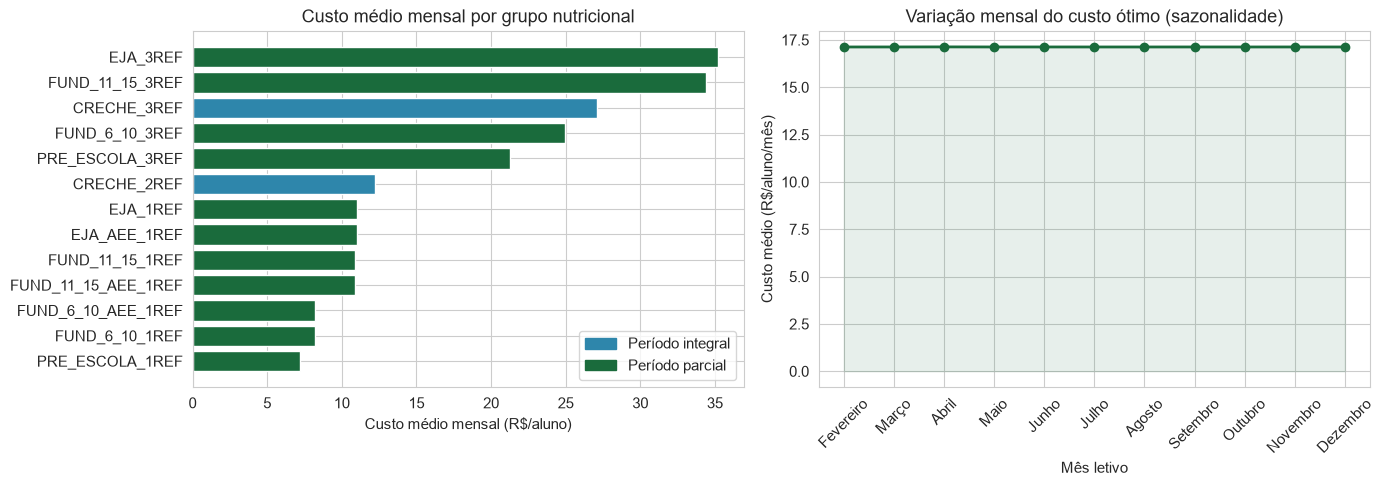

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Custo médio mensal por grupo ──────────────────────────────────
custo_grupo = df_sum_ok.groupby('grupo')['custo_total'].mean().sort_values()
cores_grupo = ['#2E86AB' if 'integral' in g.lower() or 'creche' in g.lower()
               else '#1A6B3C' for g in custo_grupo.index]

axes[0].barh(custo_grupo.index, custo_grupo.values, color=cores_grupo)
axes[0].set_xlabel('Custo médio mensal (R$/aluno)')
axes[0].set_title('Custo médio mensal por grupo nutricional')
patch_int = mpatches.Patch(color='#2E86AB', label='Período integral')
patch_par = mpatches.Patch(color='#1A6B3C', label='Período parcial')
axes[0].legend(handles=[patch_int, patch_par])

# ── Custo médio por mês (todos os grupos) ─────────────────────────
custo_mes = df_sum_ok.groupby('mes')['custo_total'].mean()
nomes_mes  = [NOMES_MESES.get(m, str(m)) for m in custo_mes.index]
axes[1].plot(nomes_mes, custo_mes.values, marker='o', color='#1A6B3C', linewidth=2)
axes[1].set_xlabel('Mês letivo')
axes[1].set_ylabel('Custo médio (R$/aluno/mês)')
axes[1].set_title('Variação mensal do custo ótimo (sazonalidade)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].fill_between(nomes_mes, custo_mes.values, alpha=0.1, color='#1A6B3C')

plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'grafico_custo_grupo_mes.png'), dpi=150, bbox_inches='tight')
plt.show()


### 6.2 Sazonalidade de custo ao longo do ano

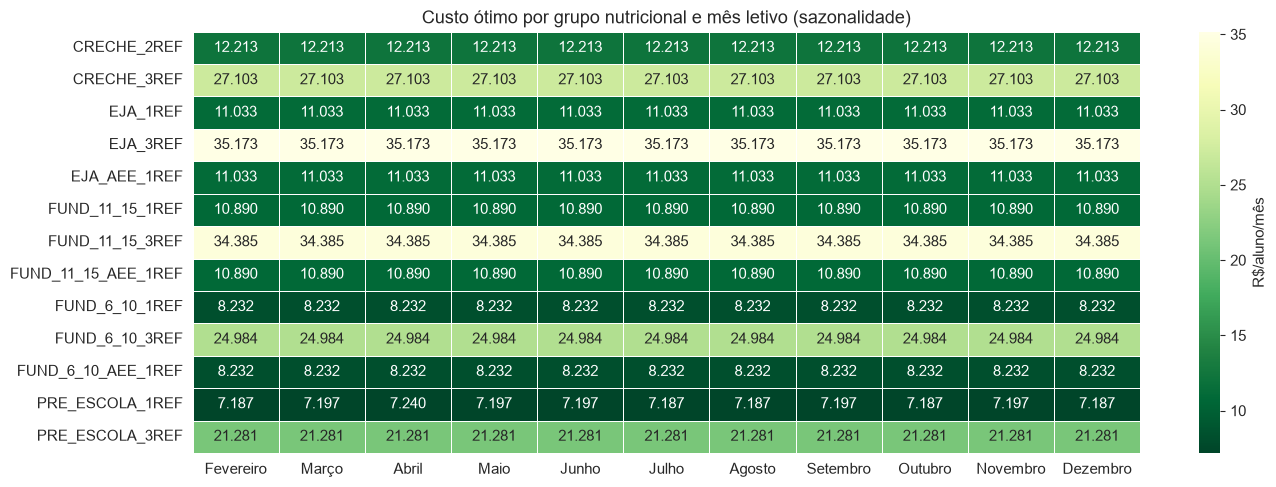

In [9]:
# ── Heatmap: custo por grupo × mês ────────────────────────────────
pivot_custo = df_sum_ok.pivot_table(
    index='grupo', columns='nome_mes', values='custo_total', aggfunc='mean'
)
# Ordenar meses cronologicamente
ordem_meses = [NOMES_MESES[m] for m in MESES_LETIVOS if NOMES_MESES[m] in pivot_custo.columns]
pivot_custo = pivot_custo[ordem_meses]

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    pivot_custo, annot=True, fmt='.3f', cmap='YlGn_r',
    linewidths=0.5, ax=ax, cbar_kws={'label': 'R$/aluno/mês'}
)
ax.set_title('Custo ótimo por grupo nutricional e mês letivo (sazonalidade)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'grafico_heatmap_sazonalidade.png'), dpi=150, bbox_inches='tight')
plt.show()


### 6.3 Conformidade nutricional consolidada

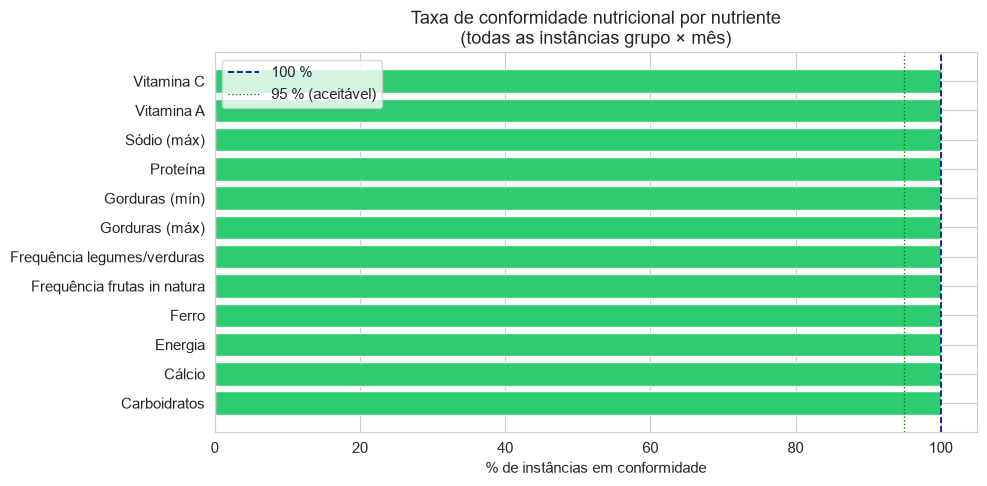

,nutriente,taxa_conformidade_pct
0,Carboidratos,100.0
1,Cálcio,100.0
2,Energia,100.0
3,Ferro,100.0
4,Frequência frutas in natura,100.0
5,Frequência legumes/verduras,100.0
6,Gorduras (máx),100.0
7,Gorduras (mín),100.0
8,Proteína,100.0
9,Sódio (máx),100.0


In [10]:
# ── Carregar tabela de conformidade ──────────────────────────────
path_conf = os.path.join(output_folder, 'conformidade_nutricional_todos.csv')
if os.path.exists(path_conf):
    df_conf = pd.read_csv(path_conf)

    # Taxa de conformidade por nutriente
    df_conf_ok = df_conf[df_conf['status'].isin(['✅','OK','Conforme'])]
    taxa = (
        df_conf.groupby('nutriente').apply(
            lambda x: (x['status'].isin(['✅','OK','Conforme'])).mean() * 100
        ).round(1)
        .reset_index()
        .rename(columns={0: 'taxa_conformidade_pct'})
        .sort_values('taxa_conformidade_pct')
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    cores = ['#2ECC71' if v >= 95 else '#E74C3C' if v < 80 else '#F39C12'
             for v in taxa['taxa_conformidade_pct']]
    ax.barh(taxa['nutriente'], taxa['taxa_conformidade_pct'], color=cores)
    ax.axvline(x=100, color='navy', linestyle='--', linewidth=1.2, label='100 %')
    ax.axvline(x=95,  color='green', linestyle=':', linewidth=1, label='95 % (aceitável)')
    ax.set_xlabel('% de instâncias em conformidade')
    ax.set_title('Taxa de conformidade nutricional por nutriente\n(todas as instâncias grupo × mês)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(output_folder, 'grafico_conformidade_nutricional.png'), dpi=150, bbox_inches='tight')
    plt.show()
    display(taxa)
else:
    print(f"⚠ {path_conf} não encontrado. Execute o solver completo (Bloco 5.2) primeiro.")


### 6.4 Indicadores de Agricultura Familiar

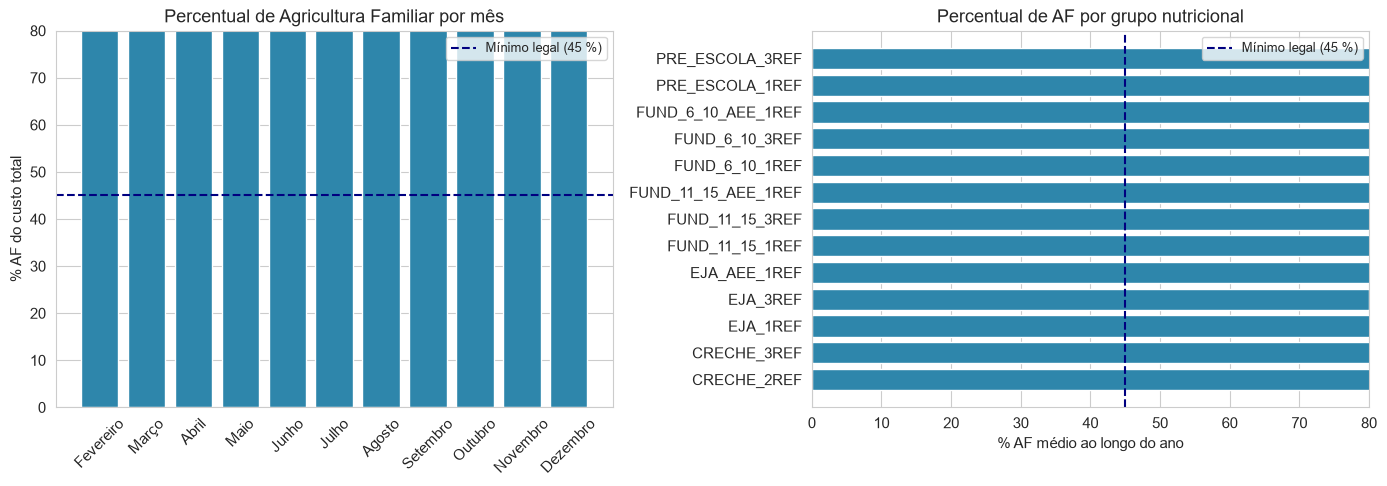

Instâncias com AF ≥ 45 % (mínimo legal): 143 / 143 (100.0 %)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── % AF por mês (média dos grupos) ──────────────────────────────
af_mes = df_sum_ok.groupby('mes')['pct_af'].mean() * 100
nomes  = [NOMES_MESES.get(m, str(m)) for m in af_mes.index]
cores_af = ['#2E86AB' if v >= 45 else '#E84855' for v in af_mes.values]

axes[0].bar(nomes, af_mes.values, color=cores_af)
# CORREÇÃO (set/2026): removida a linha de referência de 30 % — a Lei nº
# 15.226/2025 revogou esse piso; 45 % é hoje o único mínimo legal de AF
# vigente neste projeto (não mais uma "meta" acima do mínimo).
axes[0].axhline(y=45, color='navy', linestyle='--', linewidth=1.5, label='Mínimo legal (45 %)')
axes[0].set_ylabel('% AF do custo total')
axes[0].set_title('Percentual de Agricultura Familiar por mês')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 80)

# ── % AF por grupo (média dos meses) ─────────────────────────────
af_grupo = df_sum_ok.groupby('grupo')['pct_af'].mean() * 100
cores_g  = ['#2E86AB' if v >= 45 else '#E84855' for v in af_grupo.values]
axes[1].barh(af_grupo.index, af_grupo.values, color=cores_g)
# CORREÇÃO (set/2026): idem acima — 30 % removido, não está mais em vigor.
axes[1].axvline(x=45, color='navy', linestyle='--', linewidth=1.5, label='Mínimo legal (45 %)')
axes[1].set_xlabel('% AF médio ao longo do ano')
axes[1].set_title('Percentual de AF por grupo nutricional')
axes[1].legend(fontsize=9)
axes[1].set_xlim(0, 80)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'grafico_af_mes_grupo.png'), dpi=150, bbox_inches='tight')
plt.show()

n_meta = (df_sum_ok['pct_af'] >= 0.45).sum()
print(f"Instâncias com AF ≥ 45 % (mínimo legal): {n_meta} / {len(df_sum_ok)} ({n_meta/len(df_sum_ok)*100:.1f} %)")


## 7. Inspeção de cardápio — grupo e mês específicos <a id='7-inspecao'></a>

In [12]:
# ── Selecionar instância para inspeção ───────────────────────────
GRUPO_INSP          = 'CRECHE'   # altere
NUM_REFEICOES_INSP  = 3          # CORREÇÃO (set/2026): necessário para montar_perfil()
                                  # na Seção 7.3 — ver combinações disponíveis na Seção 4.
MES_INSP            = 3             # março

path_card = os.path.join(output_folder, f'cardapio_{GRUPO_INSP}_{MES_INSP:02d}.csv')
if os.path.exists(path_card):
    df_card = pd.read_csv(path_card)
else:
    # Tentar carregar do consolidado
    path_all = os.path.join(output_folder, 'cardapio_mensal_todos_grupos.csv')
    if os.path.exists(path_all):
        df_all  = pd.read_csv(path_all)
        df_card = df_all[
            (df_all['grupo'] == GRUPO_INSP) & (df_all['mes'] == MES_INSP)
        ].copy()
    else:
        raise FileNotFoundError(
            "Cardápio não encontrado. Execute o solver (Bloco 5.2 ou 5.3) primeiro."
        )

print(f"Cardápio: {GRUPO_INSP} / {NOMES_MESES.get(MES_INSP,'')}")
print(f"Total de registros: {len(df_card)}")
print(f"Alimentos distintos: {df_card['alimento'].nunique()}")
print(f"Custo total do mês : R$ {df_card['custo_r'].sum():.4f} / aluno")


Cardápio: CRECHE / Março
Total de registros: 170
Alimentos distintos: 23
Custo total do mês : R$ 26.9722 / aluno


### 7.1 Cardápio semanal detalhado

In [13]:
DIAS_SEMANA_NOMES = {1:'Segunda',2:'Terça',3:'Quarta',4:'Quinta',5:'Sexta'}

for semana in sorted(df_card['semana'].unique()):
    df_sem = df_card[df_card['semana'] == semana].copy()
    print(f"\n{'═'*65}")
    print(f"  SEMANA {semana}  —  Custo: R$ {df_sem['custo_r'].sum():.4f} / aluno")
    print(f"{'─'*65}")
    print(f"  {'Dia':<12} {'Alimento':<30} {'Qtd(g)':>7} {'R$':>8} {'AF':>4}")
    print(f"  {'─'*60}")

    for dia_n in sorted(df_sem['dia_semana'].unique()):
        df_dia = df_sem[df_sem['dia_semana'] == dia_n].sort_values('custo_r', ascending=False)
        dia_str = DIAS_SEMANA_NOMES.get(dia_n, f'Dia {dia_n}')
        for i, (_, row) in enumerate(df_dia.iterrows()):
            dia_label = dia_str if i == 0 else ''
            af_str    = '✓' if row.get('af', False) else ''
            print(f"  {dia_label:<12} {str(row['alimento'])[:30]:<30} "
                  f"{row['qtd_g']:>7.1f} {row['custo_r']:>8.4f} {af_str:>4}")



═════════════════════════════════════════════════════════════════
  SEMANA 1  —  Custo: R$ 6.7431 / aluno
─────────────────────────────────────────────────────────────────
  Dia          Alimento                        Qtd(g)       R$   AF
  ────────────────────────────────────────────────────────────
  Segunda      Feijão-verde                     242.6   0.7606    ✓
               Leite, de coco                    83.8   0.1079    ✓
               Banana, pacova, crua              55.3   0.1057    ✓
               Feijão, preto, cru                10.0   0.0624    ✓
               Feijão, carioca, cru              10.0   0.0624    ✓
               Frango, fígado, cru               10.0   0.0499     
               Coco, cru                         10.0   0.0430    ✓
               Arroz, tipo 2, cru                10.0   0.0369     
               Beterraba, crua                   10.0   0.0340    ✓
               Laranja, baía, crua               10.0   0.0325    ✓
               A

### 7.2 Distribuição de grupos alimentares

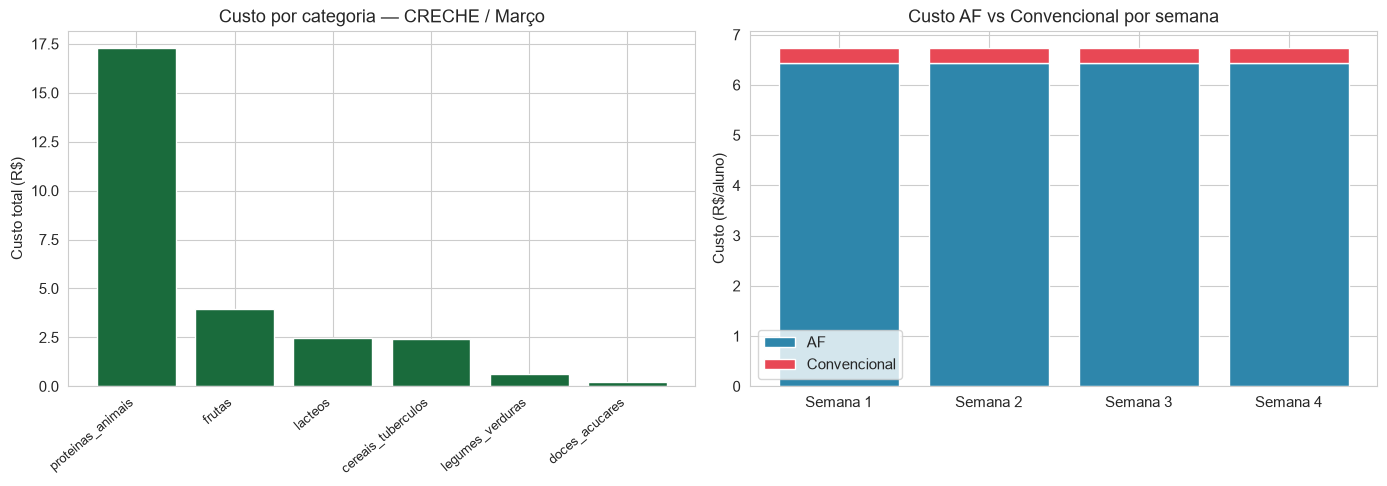

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Por categoria ─────────────────────────────────────────────────
if 'categoria' in df_card.columns:
    custo_cat = df_card.groupby('categoria')['custo_r'].sum().sort_values(ascending=False).head(10)
    axes[0].bar(range(len(custo_cat)), custo_cat.values, color='#1A6B3C')
    axes[0].set_xticks(range(len(custo_cat)))
    axes[0].set_xticklabels(custo_cat.index, rotation=40, ha='right', fontsize=9)
    axes[0].set_ylabel('Custo total (R$)')
    axes[0].set_title(f'Custo por categoria — {GRUPO_INSP} / {NOMES_MESES.get(MES_INSP,"")}')

# ── AF vs Convencional por semana ─────────────────────────────────
custo_sem_af = df_card.groupby(['semana','af'])['custo_r'].sum().unstack(fill_value=0)
semanas      = custo_sem_af.index
custo_af_v   = custo_sem_af.get(True,  pd.Series([0]*len(semanas))).values
custo_naf_v  = custo_sem_af.get(False, pd.Series([0]*len(semanas))).values

axes[1].bar(semanas, custo_af_v,  label='AF', color='#2E86AB')
axes[1].bar(semanas, custo_naf_v, label='Convencional', color='#E84855', bottom=custo_af_v)
axes[1].set_xticks(list(semanas))
axes[1].set_xticklabels([f'Semana {s}' for s in semanas])
axes[1].set_ylabel('Custo (R$/aluno)')
axes[1].set_title('Custo AF vs Convencional por semana')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(output_folder, f'grafico_cardapio_{GRUPO_INSP}_{MES_INSP:02d}.png'),
            dpi=150, bbox_inches='tight')
plt.show()


### 7.3 Verificação das restrições PNAE

In [15]:
# ── Verificar automaticamente as restrições regulatórias ──────────
perfil_insp = montar_perfil(GRUPO_INSP, NUM_REFEICOES_INSP, df_params, restricoes)

print(f"VERIFICAÇÃO DE RESTRIÇÕES — {GRUPO_INSP} ({NUM_REFEICOES_INSP} ref/dia) / {NOMES_MESES.get(MES_INSP,'')}")
print(f"{'─'*60}")

checks = []

def chk(descricao, condicao, valor, limite, unidade='', tipo='min'):
    status = '✅' if condicao else '❌'
    checks.append({
        'Restrição': descricao,
        'Valor': f"{valor:.2f} {unidade}",
        'Limite': f"{'≥' if tipo=='min' else '≤'} {limite} {unidade}",
        'Status': status
    })
    print(f"  {status} {descricao:<40} {valor:.2f} {unidade} ({'≥' if tipo=='min' else '≤'} {limite})")

# FLV por semana
for s in sorted(df_card['semana'].unique()):
    df_s   = df_card[df_card['semana']==s]
    flv_g  = df_s.loc[df_s.get('is_fruta', pd.Series(False, index=df_s.index)) |
                       df_s.get('is_legume', pd.Series(False, index=df_s.index)), 'qtd_g'].sum()
    chk(f'FLV ≥ {perfil_insp.flv_min_g_semana}g (sem {s})',
        flv_g >= perfil_insp.flv_min_g_semana, flv_g, perfil_insp.flv_min_g_semana, 'g')

# Diversidade por semana
for s in sorted(df_card['semana'].unique()):
    n_div = df_card[df_card['semana']==s]['alimento'].nunique()
    chk(f'Diversidade ≥ {perfil_insp.diversidade_min} alimentos (sem {s})',
        n_div >= perfil_insp.diversidade_min, n_div, perfil_insp.diversidade_min, 'alimentos')

# AF no mês
pct_af_card = (
    df_card.loc[df_card.get('af', pd.Series(False, index=df_card.index)).astype(bool), 'custo_r'].sum()
    / df_card['custo_r'].sum()
) if df_card['custo_r'].sum() > 0 else 0
chk('AF ≥ 45 % do custo mensal', pct_af_card >= 0.45,
    pct_af_card * 100, 45, '%')

# Limites mensais de grupos restritos
for flag, label, limite in [
    ('is_fruta',   'Cárneos ≤ 2×/mês',  perfil_insp.max_carneos_mes),
]:
    pass  # expandir conforme flags disponíveis no df_card

print()
display(pd.DataFrame(checks))


VERIFICAÇÃO DE RESTRIÇÕES — CRECHE (3 ref/dia) / Março
────────────────────────────────────────────────────────────
  ✅ FLV ≥ 520g (sem 1)                       520.01 g (≥ 520)
  ❌ FLV ≥ 520g (sem 2)                       519.99 g (≥ 520)
  ✅ FLV ≥ 520g (sem 3)                       520.01 g (≥ 520)
  ✅ FLV ≥ 520g (sem 4)                       520.00 g (≥ 520)
  ✅ Diversidade ≥ 23 alimentos (sem 1)       23.00 alimentos (≥ 23)
  ✅ Diversidade ≥ 23 alimentos (sem 2)       23.00 alimentos (≥ 23)
  ✅ Diversidade ≥ 23 alimentos (sem 3)       23.00 alimentos (≥ 23)
  ✅ Diversidade ≥ 23 alimentos (sem 4)       23.00 alimentos (≥ 23)
  ✅ AF ≥ 45 % do custo mensal                95.48 % (≥ 45)



,Restrição,Valor,Limite,Status
0,FLV ≥ 520g (sem 1),520.01 g,≥ 520 g,✅
1,FLV ≥ 520g (sem 2),519.99 g,≥ 520 g,❌
2,FLV ≥ 520g (sem 3),520.01 g,≥ 520 g,✅
3,FLV ≥ 520g (sem 4),520.00 g,≥ 520 g,✅
4,Diversidade ≥ 23 alimentos (sem 1),23.00 alimentos,≥ 23 alimentos,✅
5,Diversidade ≥ 23 alimentos (sem 2),23.00 alimentos,≥ 23 alimentos,✅
6,Diversidade ≥ 23 alimentos (sem 3),23.00 alimentos,≥ 23 alimentos,✅
7,Diversidade ≥ 23 alimentos (sem 4),23.00 alimentos,≥ 23 alimentos,✅
8,AF ≥ 45 % do custo mensal,95.48 %,≥ 45 %,✅


## 8. Análise comparativa: março vs setembro <a id='8-sazonalidade'></a>

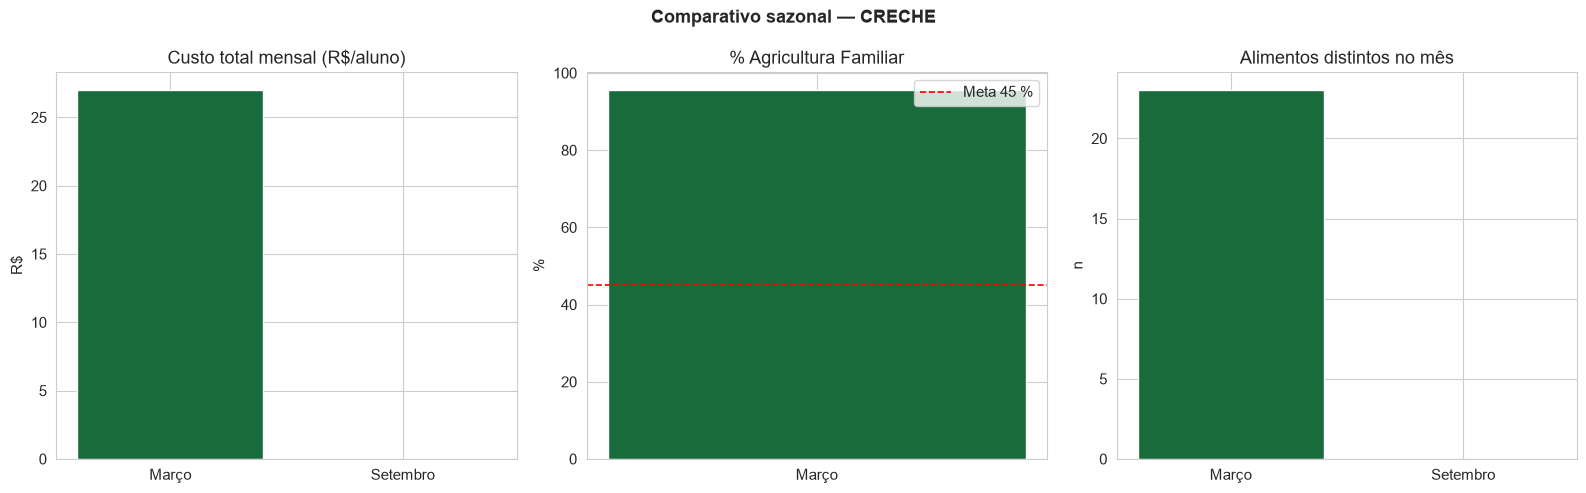


Resumo comparativo:
  Março       : R$ 26.9722 | AF 95.5 % | 23 alimentos
  Setembro    : R$ 0.0000 | AF nan % | 0 alimentos


In [16]:
# ── Comparar custo e composição entre meses sazonalmente distintos ─
GRUPO_COMP = 'CRECHE'
MESES_COMP = [3, 9]  # março (frutas tropicais) × setembro (hortaliças)

dados_comp = {}
for mes in MESES_COMP:
    path = os.path.join(output_folder, f'cardapio_{GRUPO_COMP}_{mes:02d}.csv')
    if os.path.exists(path):
        dados_comp[mes] = pd.read_csv(path)
    else:
        path_all = os.path.join(output_folder, 'cardapio_mensal_todos_grupos.csv')
        if os.path.exists(path_all):
            _all = pd.read_csv(path_all)
            dados_comp[mes] = _all[(_all['grupo']==GRUPO_COMP) & (_all['mes']==mes)].copy()

if len(dados_comp) == 2:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    custo_total_comp = {mes: df['custo_r'].sum() for mes, df in dados_comp.items()}
    pct_af_comp      = {
        mes: df.loc[df.get('af', pd.Series(False, index=df.index)).astype(bool), 'custo_r'].sum()
             / df['custo_r'].sum() * 100
        for mes, df in dados_comp.items()
    }
    n_alim_comp = {mes: df['alimento'].nunique() for mes, df in dados_comp.items()}

    nomes_c = [NOMES_MESES[m] for m in MESES_COMP]

    # Custo total
    axes[0].bar(nomes_c, [custo_total_comp[m] for m in MESES_COMP], color=['#1A6B3C','#2E86AB'])
    axes[0].set_title('Custo total mensal (R$/aluno)')
    axes[0].set_ylabel('R$')

    # % AF
    axes[1].bar(nomes_c, [pct_af_comp[m] for m in MESES_COMP], color=['#1A6B3C','#2E86AB'])
    axes[1].axhline(y=45, color='red', linestyle='--', linewidth=1.2, label='Meta 45 %')
    axes[1].set_title('% Agricultura Familiar')
    axes[1].set_ylabel('%')
    axes[1].legend()

    # Diversidade
    axes[2].bar(nomes_c, [n_alim_comp[m] for m in MESES_COMP], color=['#1A6B3C','#2E86AB'])
    axes[2].set_title('Alimentos distintos no mês')
    axes[2].set_ylabel('n')

    plt.suptitle(f'Comparativo sazonal — {GRUPO_COMP}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_folder, f'grafico_sazonalidade_{GRUPO_COMP}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()

    print("\nResumo comparativo:")
    for mes in MESES_COMP:
        print(f"  {NOMES_MESES[mes]:12s}: R$ {custo_total_comp[mes]:.4f} | "
              f"AF {pct_af_comp[mes]:.1f} % | {n_alim_comp[mes]} alimentos")
else:
    print("⚠ Dados de março e/ou setembro não disponíveis. Execute o solver para esses meses.")


## 9. Análise de sensibilidade <a id='9-sensibilidade'></a>

## 10. Geração do relatório Word para nutricionistas <a id='10-relatorio'></a>

> **Atualização (jul/2026):** A geração do relatório para nutricionista passa a ser um passo manual, executado separadamente:
> ```bash
> python gerar_relatorio_pnae.py
> ```


### Como atualizar o relatório Word

Sempre que houver atualização de dados (novos preços, novos meses, ajuste de parâmetros):

```bash
# 1. Re-executar o solver para os meses atualizados
python otimizacao_pnae_solver.py --meses 3 9 --output ./data/output/

# 2. Gerar o relatório Word com dados reais (fora deste notebook)
python gerar_relatorio_pnae.py
```


## 11. Exportação final consolidada <a id='11-exportacao'></a>

In [17]:
# ── Verificar e listar todos os arquivos de saída gerados ─────────
print(f"ARQUIVOS DE SAÍDA — {output_folder}")
print(f"{'─'*65}")

arquivos_saida = {
    # Solver parciais (por instância)
    'cardapio_<GRUPO>_<MES>.csv'          : 'Cardápio por grupo/mês (gerado pelo solver)',
    # Consolidados
    'cardapio_mensal_todos_grupos.csv'    : 'Cardápio consolidado todos os grupos e meses',
    'conformidade_nutricional_todos.csv'  : 'Conformidade nutricional por instância',
    'sumario_otimizacao_todos.csv'        : 'Sumário de indicadores (custo, AF, status)',
    'sumario_otimizacao_todos.json'       : 'Sumário JSON (para integração com outros sistemas)',
    # Gráficos
    'grafico_custo_grupo_mes.png'         : 'Custo por grupo e variação mensal',
    'grafico_heatmap_sazonalidade.png'    : 'Heatmap de sazonalidade de custo',
    'grafico_conformidade_nutricional.png': 'Taxa de conformidade por nutriente',
    'grafico_af_mes_grupo.png'            : 'Indicadores de AF por mês e grupo',
    'grafico_sensibilidade_af.png'        : 'Sensibilidade do custo à meta AF',
}

for nome, descricao in arquivos_saida.items():
    if '*' in nome or '<' in nome:
        padrao = nome.replace('<GRUPO>', '*').replace('<MES>', '*')
        import glob
        encontrados = glob.glob(os.path.join(output_folder, padrao))
        status = f"✓ {len(encontrados)} arquivos" if encontrados else "⚠ nenhum gerado"
    else:
        path = os.path.join(output_folder, nome)
        if os.path.exists(path):
            kb = os.path.getsize(path) // 1024
            status = f"✓ {kb} KB"
        else:
            status = "⚠ ausente"
    print(f"  {status:20s} {nome}")
    print(f"  {'':20s} → {descricao}")
    print()


ARQUIVOS DE SAÍDA — ./data/output/
─────────────────────────────────────────────────────────────────
  ✓ 145 arquivos       cardapio_<GRUPO>_<MES>.csv
                       → Cardápio por grupo/mês (gerado pelo solver)

  ✓ 1839 KB            cardapio_mensal_todos_grupos.csv
                       → Cardápio consolidado todos os grupos e meses

  ✓ 96 KB              conformidade_nutricional_todos.csv
                       → Conformidade nutricional por instância

  ✓ 11 KB              sumario_otimizacao_todos.csv
                       → Sumário de indicadores (custo, AF, status)

  ✓ 44 KB              sumario_otimizacao_todos.json
                       → Sumário JSON (para integração com outros sistemas)

  ✓ 109 KB             grafico_custo_grupo_mes.png
                       → Custo por grupo e variação mensal

  ✓ 238 KB             grafico_heatmap_sazonalidade.png
                       → Heatmap de sazonalidade de custo

  ✓ 70 KB              grafico_conformidade_nutricio

## 12. Sumário executivo <a id='12-sumario'></a>

In [18]:
# ── Imprimir sumário executivo consolidado ────────────────────────
print("═"*65)
print("SUMÁRIO EXECUTIVO — Otimização PNAE (Módulo 5)")
print(f"Gerado em: {datetime.now().strftime('%d/%m/%Y %H:%M')}")
print("═"*65)

print(f"\n1. ESCOPO")
print(f"   Município     : Salvador — BA")
print(f"   Meses letivos : {len(MESES_LETIVOS)} (fevereiro a dezembro; janeiro excluído)")
print(f"   Grupos        : {df_params['grupo_nutricional'].nunique()}")
print(f"   Horizonte     : {DIAS_UTEIS_MES} dias úteis por mês (4 semanas × 5 dias)")
print(f"   Fonte legal   : Resolução CD/FNDE nº 4/2026 + Lei nº 11.947/2009")

if 'df_sum_ok' in dir() and len(df_sum_ok):
    print(f"\n2. RESULTADOS")
    print(f"   Instâncias ótimas     : {len(df_sum_ok)} / {len(df_sum)}")
    print(f"   Custo médio/aluno/mês : R$ {df_sum_ok['custo_total'].mean():.4f}")
    print(f"   Custo mín/aluno/mês   : R$ {df_sum_ok['custo_total'].min():.4f}")
    print(f"   Custo máx/aluno/mês   : R$ {df_sum_ok['custo_total'].max():.4f}")
    print(f"   % AF médio            : {df_sum_ok['pct_af'].mean()*100:.1f} %")
    print(f"   % instâncias AF ≥ 45 %: {(df_sum_ok['pct_af']>=0.45).mean()*100:.1f} %")
    print(f"   Alimentos/solução (médio): {df_sum_ok['n_alimentos'].mean():.0f}")

print(f"\n3. ARQUIVOS GERADOS")
print(f"   Pasta: {os.path.abspath(output_folder)}")
print(f"   Relatório Word: relatorio_pnae_nutricionistas.docx "
      f"(gere separadamente com: python gerar_relatorio_pnae.py)")

print(f"\n4. MODELO MATEMÁTICO")
print(f"   Tipo     : MILP (Mixed Integer Linear Program)")
print(f"   Solver   : PuLP / CBC (COIN-OR)")
print(f"   Variáveis: x_jd (quantidade) + y_jd (presença) + z_j (diversidade)")
print(f"   Restrições principais (27): R01-R07 nutricionais mínimas,")
print(f"              R08 sódio máx, R09-R10 lipídeos, R11-R13 vinculação x↔y,")
print(f"              R14 diversidade semanal, R15 FLV, R16-R19 frequência grupos,")
print(f"              R20-R26 limites mensais, R27 AF ≥ 45 %")
print("═"*65)


═════════════════════════════════════════════════════════════════
SUMÁRIO EXECUTIVO — Otimização PNAE (Módulo 5)
Gerado em: 08/09/2026 10:44
═════════════════════════════════════════════════════════════════

1. ESCOPO
   Município     : Salvador — BA
   Meses letivos : 11 (fevereiro a dezembro; janeiro excluído)
   Grupos        : 8
   Horizonte     : 20 dias úteis por mês (4 semanas × 5 dias)
   Fonte legal   : Resolução CD/FNDE nº 4/2026 + Lei nº 11.947/2009

2. RESULTADOS
   Instâncias ótimas     : 143 / 143
   Custo médio/aluno/mês : R$ 17.1267
   Custo mín/aluno/mês   : R$ 7.1871
   Custo máx/aluno/mês   : R$ 35.1730
   % AF médio            : 88.7 %
   % instâncias AF ≥ 45 %: 100.0 %
   Alimentos/solução (médio): 18

3. ARQUIVOS GERADOS
   Pasta: c:\Users\dba14\Documents\projeto\PNAE\data\output
   Relatório Word: relatorio_pnae_nutricionistas.docx (gere separadamente com: python gerar_relatorio_pnae.py)

4. MODELO MATEMÁTICO
   Tipo     : MILP (Mixed Integer Linear Program)
   S